<a href="https://colab.research.google.com/github/indicadorel-ui/FundamentosDeSimulacionyModelacionProbabilistica/blob/main/Modelaci%C3%B3n_y_Simulaci%C3%B3n_de_Procesos_Estoc%C3%A1sticos_JEVM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# **FACULTAD DE CIENCIAS EXACTAS**

### **MAESTRÍA EN ESTADÍSTICA APLICADA**

<br>

---

<br>

**ASIGNATURA**

# SIMULACIÓN ESTOCÁSTICA

<br>

**PROYECTO DE INVESTIGACIÓN**



> *Estimación bayesiana de la intensidad de goles en partidos de la Liga MX mediante Cadenas de Markov Monte Carlo (MCMC).*




<br>
<br>
<br>

| **DOCENTE** | **PRESENTA** |
|:----:|:----:|
| Dr. Gerónimo Quiñonez Barraza | Jesús Emmanuel Vázquez Macías |

<br>
<br>

---

<br>

**FECHA DE ENTREGA**

## 14 de noviembre de 2026

<br>






# **1. Librerías y entorno computacional**

Para el desarrollo de esta investigación se utilizará Python como lenguaje de programación, mediante el entorno de Google Colab.

Se emplearán distintas bibliotecas especializadas en extracción, procesamiento y análisis de datos, así como en simulación estocástica, inferencia bayesiana y visualización estadística.

La información empírica se obtendrá **mediante la API de ESPN, utilizando los registros históricos de partidos de la Liga MX**. Posteriormente, estos datos serán procesados para construir un modelo probabilístico que permita estimar las intensidades de goles de los equipos bajo las condiciones de local y visitante.

La implementación computacional del modelo se realizará mediante el algoritmo Metropolis-Hastings, utilizando simulación Monte Carlo vía cadenas de Markov (MCMC).

<br>

# **2. Descripción de las herramientas computacionales**

Las bibliotecas utilizadas cumplen las siguientes funciones:

| Biblioteca | Función dentro del proyecto |
|---|---|
| Pandas | Organización, limpieza y manipulación de los datos de partidos. |
| NumPy | Operaciones numéricas y generación de números aleatorios. |
| Requests | Conexión y extracción de información desde la API de ESPN. |
| Matplotlib | Elaboración de gráficas estadísticas. |
| Seaborn | Visualización de distribuciones y patrones estadísticos. |
| SciPy | Funciones de probabilidad y herramientas matemáticas. |
| ArviZ | Diagnóstico de convergencia, R-hat, ESS y análisis de cadenas MCMC. |
| OpenPyXL | Exportación de los resultados a archivos Excel. |


Se establece **una semilla aleatoria con valor de 42** para favorecer la reproducibilidad de los experimentos computacionales. Esto permite obtener resultados consistentes cuando se repite la simulación bajo las mismas condiciones iniciales y configuraciones.

La configuración gráfica se establece para facilitar la interpretación de las distribuciones de probabilidad, las trayectorias de las cadenas y los diagnósticos estadísticos.

# **Web Scraping**

Este script de Python está diseñado para automatizar la extracción de información y estadísticas de todos los partidos de la Liga MX directamente desde las APIs oficiales de ESPN, consolidando los datos y generando un archivo de Excel (.xlsx) listo para descargar en Google Colab.

**¿Qué hace exactamente paso a paso?**
1. **Descubre los equipos**: Consulta la lista completa de los 18 clubes de la Liga MX de forma automática.

2. **Revisa los calendarios**: Entra al calendario de cada equipo de manera iterativa para obtener su historial de encuentros.

3. **Extrae métricas clave**: Por cada partido, recopila datos precisos como:

*   Fecha del encuentro.
*   Nombre del rival.
*   Condición (Local o Visitante).
*   Goles a favor y goles en contra.
*   Estado del partido (si ya finalizó).

4. **Exporta a Excel**: Utiliza la librería pandas para limpiar duplicados, organizar toda la información en una tabla estructurada y guardarla automáticamente en un archivo de Excel (liga_mx_todos_los_partidos.xlsx).

In [1]:
import pandas as pd
import requests

# 1. Obtener la lista de todos los equipos de la Liga MX (mex.1)
url_teams = (
    "https://site.api.espn.com/apis/site/v2/sports/soccer/mex.1/teams?limit=50"
)
response_teams = requests.get(url_teams)

if response_teams.status_code != 200:
    print("Error al conectar con la API de ESPN para obtener los equipos.")
else:
    teams_data = response_teams.json()
    # Dependiendo de la estructura de la API, los equipos pueden venir bajo 'sports' -> 'leagues' -> 'teams'
    try:
        equipos_lista = teams_data["sports"][0]["leagues"][0]["teams"]
    except KeyError:
        # Estructura alternativa común en la API de ESPN
        equipos_lista = (
            teams_data.get("sports", [{}])[0]
            .get("leagues", [{}])[0]
            .get("teams", [])
        )

    todos_los_partidos = []

    print(
        f"Se encontraron {len(equipos_lista)} equipos. Extrayendo calendarios..."
    )

    # 2. Iterar por cada equipo para extraer su calendario y resultados
    for item in equipos_lista:
        team_info = item.get("team", {})
        team_id = team_info.get("id")
        team_name = team_info.get("displayName")

        print(f"Procesando equipo: {team_name} (ID: {team_id})")

        url_schedule = f"https://site.api.espn.com/apis/site/v2/sports/soccer/mex.1/teams/{team_id}/schedule"
        res_sched = requests.get(url_schedule)

        if res_sched.status_code == 200:
            sched_data = res_sched.json()
            events = sched_data.get("events", [])

            for ev in events:
                game_id = ev.get("id")
                fecha = ev.get("date", "")[:10]  # Fecha YYYY-MM-DD
                nombre_evento = ev.get("name")

                competitions = ev.get("competitions", [])
                if not competitions:
                    continue

                comp = competitions[0]
                status_type = (
                    comp.get("status", {}).get("type", {}).get("name")
                )  # Ej. STATUS_FINAL

                # Solo procesar partidos que ya se jugaron (o extraer lo que esté disponible)
                competitors = comp.get("competitors", [])

                team_score = None
                opponent_score = None
                opponent_name = None
                es_local = False
                resultado_estado = status_type

                for comp_team in competitors:
                    t_item = comp_team.get("team", {})
                    t_id = t_item.get("id")
                    score_val = comp_team.get("score", {}).get("value", None)

                    if str(t_id) == str(team_id):
                        team_score = score_val
                        es_local = (
                            comp_team.get("homeAway") == "home"
                        )
                    else:
                        opponent_name = t_item.get("displayName")
                        opponent_score = score_val

                # Guardar el registro
                todos_los_partidos.append(
                    {
                        "Equipo": team_name,
                        "ID_Equipo": team_id,
                        "Fecha": fecha,
                        "Rival": opponent_name,
                        "Condicion": "Local" if es_local else "Visita",
                        "Goles_Favor": team_score,
                        "Goles_En_Contra": opponent_score,
                        "Estado": resultado_estado,
                        "Partido": nombre_evento,
                        "ID_Juego": game_id,
                    }
                )

    # 3. Convertir a DataFrame de Pandas
    df_partidos = pd.DataFrame(todos_los_partidos)

    # Limpiar duplicados si los hay (ya que el calendario de un equipo y su rival pueden solaparse)
    df_partidos = df_partidos.drop_duplicates(subset=["ID_Juego", "ID_Equipo"])

    print(
        f"\n¡Proceso terminado! Se recopilaron {len(df_partidos)} registros de partidos."
    )

    # Mostrar las primeras filas
    display(df_partidos.head(10))

    # 4. Descargar automáticamente el archivo en Google Colab
    nombre_archivo = "liga_mx_todos_los_partidos.xlsx"
    df_partidos.to_excel(nombre_archivo, index=False)
    print(f"\nArchivo guardado y listo para descargar como: {nombre_archivo}")

Se encontraron 18 equipos. Extrayendo calendarios...
Procesando equipo: América (ID: 227)
Procesando equipo: Atlante (ID: 226)
Procesando equipo: Atlas (ID: 216)
Procesando equipo: Atlético de San Luis (ID: 15720)
Procesando equipo: Cruz Azul (ID: 218)
Procesando equipo: FC Juárez (ID: 17851)
Procesando equipo: Guadalajara (ID: 219)
Procesando equipo: León (ID: 228)
Procesando equipo: Monterrey (ID: 220)
Procesando equipo: Necaxa (ID: 229)
Procesando equipo: Pachuca (ID: 234)
Procesando equipo: Puebla (ID: 231)
Procesando equipo: Pumas UNAM (ID: 233)
Procesando equipo: Querétaro (ID: 222)
Procesando equipo: Santos (ID: 225)
Procesando equipo: Tigres UANL (ID: 232)
Procesando equipo: Tijuana (ID: 10125)
Procesando equipo: Toluca (ID: 223)

¡Proceso terminado! Se recopilaron 286 registros de partidos.


,Equipo,ID_Equipo,Fecha,Rival,Condicion,Goles_Favor,Goles_En_Contra,Estado,Partido,ID_Juego
0,América,227,2026-11-08,Pumas UNAM,Visita,2.0,2.0,STATUS_FULL_TIME,América at Pumas UNAM,401876904
1,América,227,2026-11-01,Toluca,Local,2.0,2.0,STATUS_FULL_TIME,Toluca at América,401876913
2,América,227,2026-10-29,Tijuana,Local,1.0,1.0,STATUS_FULL_TIME,Tijuana at América,401876986
3,América,227,2026-10-26,Pachuca,Local,1.0,2.0,STATUS_FULL_TIME,Pachuca at América,401876922
4,América,227,2026-10-22,Atlas,Visita,5.0,2.0,STATUS_FULL_TIME,América at Atlas,401876932
5,América,227,2026-10-18,León,Visita,5.0,3.0,STATUS_FULL_TIME,América at León,401876941
6,América,227,2026-10-11,Monterrey,Local,1.0,1.0,STATUS_FULL_TIME,Monterrey at América,401876950
7,América,227,2026-09-28,Necaxa,Visita,4.0,2.0,STATUS_FULL_TIME,América at Necaxa,401876956
8,América,227,2026-09-20,Guadalajara,Local,2.0,2.0,STATUS_FULL_TIME,Guadalajara at América,401876968
9,América,227,2026-09-13,Cruz Azul,Visita,3.0,4.0,STATUS_FULL_TIME,América at Cruz Azul,401876981



Archivo guardado y listo para descargar como: liga_mx_todos_los_partidos.xlsx


# **3. Fundamentos matemáticos y probabilísticos**

##**3.1. Cadenas de Markov y métodos Monte Carlo**

Los métodos Monte Carlo constituyen una familia de procedimientos numéricos que utilizan números aleatorios para aproximar cantidades matemáticas, integrales y distribuciones de probabilidad que pueden resultar difíciles de resolver analíticamente.

Dentro de estos métodos se encuentran las cadenas de Markov Monte Carlo (MCMC), las cuales permiten generar muestras aleatorias dependientes entre sí, cuya distribución estacionaria corresponde a una distribución de probabilidad objetivo.

Una cadena de Markov es un proceso estocástico que satisface la propiedad de Markov, es decir, el estado futuro depende únicamente del estado actual y no de toda la trayectoria previa del proceso.

Matemáticamente, esta propiedad se expresa como:

$$
P(X_{t+1}=x_{t+1}\mid X_t=x_t,\ldots,X_0=x_0)
=
P(X_{t+1}=x_{t+1}\mid X_t=x_t)
$$

Donde:

- $X_t$ representa el estado actual de la cadena.
- $X_{t+1}$ representa el siguiente estado.
- $P$ representa la probabilidad de transición entre estados.

En esta investigación, los estados de la cadena estarán representados por los valores propuestos para los parámetros de intensidad de goles de los equipos locales y visitantes.

El objetivo es construir cadenas de Markov cuya distribución estacionaria permita aproximar las distribuciones posteriores de dichos parámetros.

## **3.2. Modelo probabilístico de goles**

Para representar el número de goles anotados durante un partido de fútbol se utilizará la distribución de Poisson, debido a que se trata de una variable aleatoria discreta que representa la ocurrencia de eventos en un intervalo determinado.

Se definirán dos variables aleatorias:

**Goles del equipo local:**

$$
Y_{L,i}\sim Poisson(\lambda_L)
$$

**Goles del equipo visitante:**

$$
Y_{V,i}\sim Poisson(\lambda_V)
$$

Donde:

- $Y_{L,i}$ representa los goles anotados por el equipo local en el partido $i$.
- $Y_{V,i}$ representa los goles anotados por el equipo visitante en el partido $i$.
- $\lambda_L$ representa la intensidad promedio de goles de los equipos locales.
- $\lambda_V$ representa la intensidad promedio de goles de los equipos visitantes.

La función de probabilidad de una distribución de Poisson está definida por:

$$
P(Y=y\mid\lambda)=
\frac{e^{-\lambda}\lambda^y}{y!}
$$

Donde $y$ representa el número observado de goles y $\lambda$ es el parámetro de intensidad.

En este modelo se considera inicialmente que los goles locales y visitantes siguen distribuciones de Poisson independientes, condicionadas a sus respectivos parámetros.

Esta formulación permite estimar y comparar la intensidad de anotación bajo ambas condiciones de juego.

## **3.3. Distribución previa de los parámetros**

Para realizar inferencia bayesiana es necesario establecer una distribución previa que represente el conocimiento inicial sobre los parámetros antes de incorporar los datos observados.

Se utilizarán distribuciones Gamma para los parámetros de intensidad de goles locales y visitantes:

$$
\lambda_L\sim Gamma(\alpha_L,\beta_L)
$$

$$
\lambda_V\sim Gamma(\alpha_V,\beta_V)
$$

Se utilizará la parametrización Gamma con parámetros de forma y tasa (*shape-rate*).

Para este estudio se proponen inicialmente los siguientes valores:

$$
\alpha_L=2,\qquad \beta_L=1
$$

$$
\alpha_V=2,\qquad \beta_V=1
$$

Estas distribuciones previas representan una expectativa inicial de dos goles por partido, con incertidumbre suficiente para permitir que los datos observados actualicen las estimaciones.

La función de densidad de la distribución Gamma está definida por:

$$
p(\lambda)=
\frac{\beta^\alpha}{\Gamma(\alpha)}
\lambda^{\alpha-1}e^{-\beta\lambda}
$$

Donde:

- $\alpha$ representa el parámetro de forma.
- $\beta$ representa el parámetro de tasa.
- $\Gamma(\alpha)$ representa la función Gamma.
- $\lambda$ representa la intensidad de goles.

La media y la varianza de esta distribución se calculan mediante:

$$
E(\lambda)=\frac{\alpha}{\beta}
$$

$$
Var(\lambda)=\frac{\alpha}{\beta^2}
$$

La elección de una distribución previa Gamma facilita la formulación matemática del modelo, debido a su conjugación con la distribución de Poisson.

## **3.4. Distribución posterior mediante el teorema de Bayes**

La inferencia bayesiana permite actualizar el conocimiento sobre los parámetros del modelo mediante la incorporación de los datos observados.

El teorema de Bayes establece:

$$
p(\lambda\mid Y)=
\frac{p(Y\mid\lambda)p(\lambda)}
{p(Y)}
$$

Donde:

- $p(\lambda\mid Y)$ representa la distribución posterior.
- $p(Y\mid\lambda)$ representa la función de verosimilitud.
- $p(\lambda)$ representa la distribución previa.
- $p(Y)$ representa la evidencia marginal.

Para los goles locales, suponiendo observaciones independientes y una intensidad constante, la función de verosimilitud es:

$$
L(\lambda_L\mid Y_L)
\propto
\lambda_L^{\sum_{i=1}^{n}Y_{L,i}}
e^{-n\lambda_L}
$$

Al combinar esta función con la distribución previa Gamma, se obtiene la distribución posterior:

$$
\lambda_L\mid Y_L
\sim
Gamma\left(
\alpha_L+\sum_{i=1}^{n}Y_{L,i},
\beta_L+n
\right)
$$

De manera equivalente, para los goles visitantes:

$$
\lambda_V\mid Y_V
\sim
Gamma\left(
\alpha_V+\sum_{i=1}^{n}Y_{V,i},
\beta_V+n
\right)
$$

Estas expresiones representan las distribuciones posteriores de los parámetros de intensidad de goles locales y visitantes.

La media posterior permitirá estimar el promedio esperado de anotaciones bajo cada condición, mientras que los intervalos de credibilidad permitirán cuantificar la incertidumbre asociada a dichas estimaciones.

## **3.5. Probabilidades de transición y distribución estacionaria**

Para obtener muestras de las distribuciones posteriores mediante MCMC se utilizará el algoritmo Metropolis-Hastings.

El procedimiento consiste en proponer un nuevo valor para el parámetro de interés y evaluar si debe aceptarse o rechazarse.

Sea $\lambda^{(t)}$ el estado actual de la cadena y $\lambda^*$ el valor propuesto.

La probabilidad de aceptación se expresa mediante:

$$
a(\lambda^{(t)},\lambda^*)=
\min\left[
1,
\frac{
\pi(\lambda^*)q(\lambda^{(t)}\mid\lambda^*)
}{
\pi(\lambda^{(t)})q(\lambda^*\mid\lambda^{(t)})
}
\right]
$$

Donde:

- $\pi(\lambda)$ representa la distribución objetivo, en este caso la distribución posterior.
- $q(\lambda^*\mid\lambda^{(t)})$ representa la distribución de propuesta.
- $a$ representa la probabilidad de aceptación.

Si la propuesta es aceptada, el nuevo estado será:

$$
\lambda^{(t+1)}=\lambda^*
$$

En caso contrario, la cadena conserva el estado anterior:

$$
\lambda^{(t+1)}=\lambda^{(t)}
$$

La distribución estacionaria representa la distribución de probabilidad que permanece invariante bajo las transiciones de la cadena.

Para este estudio, se busca que la distribución estacionaria de las cadenas generadas corresponda a las distribuciones posteriores de los parámetros $\lambda_L$ y $\lambda_V$.

Para garantizar el comportamiento adecuado del algoritmo se considerarán condiciones como irreducibilidad, aperiodicidad y recurrencia positiva, además de evaluar empíricamente la convergencia y mezcla de las cadenas.

## **3.6. Interpretación de los fundamentos matemáticos**

El modelo probabilístico propuesto permite representar el comportamiento de los goles anotados por los equipos locales y visitantes mediante distribuciones de Poisson.

La incorporación de distribuciones previas Gamma permite desarrollar un enfoque bayesiano, mediante el cual los parámetros de intensidad de goles se actualizan a partir de la información empírica obtenida de los partidos de la Liga MX.

La distribución posterior constituye el objetivo de la simulación MCMC. Mediante el algoritmo Metropolis-Hastings se generarán cadenas de Markov que permitirán obtener muestras de dicha distribución y estimar los parámetros de interés.

Finalmente, la comparación entre las distribuciones posteriores de los equipos locales y visitantes permitirá evaluar la posible existencia de una ventaja asociada a la condición de localía.

Es importante señalar que el modelo inicial supone independencia entre los goles locales y visitantes, así como una intensidad constante dentro del periodo analizado. Estos supuestos serán considerados al interpretar los resultados y discutir las limitaciones de la investigación.

# **4. Selección del algoritmo MCMC**

## **4.1. Algoritmo seleccionado: Metropolis-Hastings**

Para el desarrollo de esta investigación se seleccionó el algoritmo Metropolis-Hastings, perteneciente a los métodos Monte Carlo vía cadenas de Markov (MCMC).

Este algoritmo permite generar muestras de una distribución de probabilidad objetivo mediante la construcción de una cadena de Markov, utilizando un mecanismo de aceptación y rechazo de valores propuestos.

La elección de Metropolis-Hastings se justifica por su flexibilidad para trabajar con distribuciones posteriores y porque permite realizar inferencia bayesiana sin necesidad de conocer la constante de normalización de la distribución objetivo.

En esta investigación se utilizará para estimar los parámetros de intensidad de goles de los equipos locales y visitantes de la Liga MX, representados por $\lambda_L$ y $\lambda_V$, respectivamente.

El propósito será obtener muestras de sus distribuciones posteriores y calcular estimaciones estadísticas que permitan comparar el comportamiento ofensivo bajo ambas condiciones de juego.

## **4.2. Justificación de la elección del algoritmo**

Se seleccionó Metropolis-Hastings por las siguientes razones:

1. **Flexibilidad probabilística:** permite trabajar con distribuciones posteriores cuya forma puede resultar compleja de evaluar directamente.

2. **Implementación computacional:** su procedimiento puede desarrollarse mediante Python utilizando operaciones matemáticas y generación de números aleatorios.

3. **Inferencia bayesiana:** permite obtener muestras de los parámetros desconocidos a partir de una distribución posterior construida mediante el teorema de Bayes.

4. **Diagnóstico estadístico:** genera cadenas de Markov cuyo comportamiento puede analizarse mediante trayectorias, autocorrelación, tamaño efectivo de muestra y estadísticos de convergencia.

5. **Comparación de parámetros:** permite construir cadenas independientes para estimar la intensidad de goles locales y visitantes.

Aunque el modelo Poisson-Gamma utilizado en esta investigación posee una distribución posterior conocida analíticamente, se implementará Metropolis-Hastings con fines de simulación y aprendizaje metodológico. Esto permitirá contrastar las estimaciones obtenidas mediante MCMC con los resultados analíticos del modelo bayesiano.

## **4.3. Fundamento matemático del algoritmo**

El algoritmo Metropolis-Hastings parte de un valor inicial para el parámetro que se desea estimar y genera propuestas sucesivas utilizando una distribución de transición.

Sea $\lambda^{(t)}$ el estado actual de la cadena y $\lambda^*$ un nuevo valor propuesto.

La propuesta se genera mediante una distribución:

$$
\lambda^*\sim q(\lambda^*\mid\lambda^{(t)})
$$

Posteriormente, se calcula la probabilidad de aceptación:

$$
a=
\min\left(
1,
\frac{
\pi(\lambda^*)q(\lambda^{(t)}\mid\lambda^*)
}{
\pi(\lambda^{(t)})q(\lambda^*\mid\lambda^{(t)})
}
\right)
$$

Donde:

- $\pi(\lambda)$ representa la distribución posterior objetivo.
- $q$ representa la distribución utilizada para generar propuestas.
- $a$ representa la probabilidad de aceptar el nuevo estado.

Se genera un número aleatorio $u$ a partir de una distribución uniforme:

$$
u\sim Uniforme(0,1)
$$

La regla de decisión es:

$$
\lambda^{(t+1)}=
\begin{cases}
\lambda^*, & \text{si } u\leq a\\
\lambda^{(t)}, & \text{si } u>a
\end{cases}
$$

De esta manera, la cadena puede avanzar hacia nuevos valores o permanecer en el estado anterior, dependiendo de la probabilidad de aceptación.

## **4.4. Distribución de propuesta**

Para este estudio se utilizará una distribución de propuesta lognormal, debido a que los parámetros de intensidad de goles deben ser estrictamente positivos.

La propuesta se define como:

$$
\log(\lambda^*)=
\log(\lambda^{(t)})+\epsilon
$$

Donde:

$$
\epsilon\sim N(0,\sigma^2)
$$

El parámetro $\sigma$ controla la magnitud de los movimientos propuestos dentro de la cadena.

Esta distribución permite generar valores positivos de manera natural y evita propuestas negativas para los parámetros de intensidad de goles.

Debido a que la distribución de propuesta no es simétrica en la escala original de $\lambda$, se incorporará la corrección correspondiente en la probabilidad de aceptación de Metropolis-Hastings.

## **4.5. Aplicación al modelo de goles de la Liga MX**

El algoritmo se aplicará de manera independiente a los parámetros de intensidad de goles locales y visitantes.

Para los equipos locales:

$$
\lambda_L\mid Y_L
\sim
Gamma\left(
\alpha_L+\sum_{i=1}^{n}Y_{L,i},
\beta_L+n
\right)
$$

Para los equipos visitantes:

$$
\lambda_V\mid Y_V
\sim
Gamma\left(
\alpha_V+\sum_{i=1}^{n}Y_{V,i},
\beta_V+n
\right)
$$

A partir de estas distribuciones posteriores se construirán dos cadenas de Markov independientes.

El procedimiento permitirá obtener muestras de ambas distribuciones y calcular:

- Media posterior de goles locales y visitantes.
- Mediana de las distribuciones posteriores.
- Varianza y desviación estándar.
- Intervalos de credibilidad del 95 %.
- Diferencia entre las intensidades de goles locales y visitantes.

La diferencia entre los parámetros se representará mediante:

$$
\Delta=\lambda_L-\lambda_V
$$

Un valor positivo de $\Delta$ indicaría una mayor intensidad promedio de anotación de los equipos locales, mientras que un valor negativo indicaría una mayor intensidad de los equipos visitantes.

También se estimará la probabilidad posterior:

$$
P(\lambda_L>\lambda_V\mid Y_L,Y_V)
$$

Esta probabilidad permitirá evaluar qué tan consistente es la evidencia estadística con la existencia de una ventaja ofensiva asociada a la condición de localía.

## **4.6. Procedimiento computacional**

La implementación del algoritmo se desarrollará mediante las siguientes etapas:

1. Obtener los registros de goles locales y visitantes a partir de los partidos recopilados mediante la API de ESPN.
2. Definir las distribuciones previas Gamma para los parámetros de intensidad.
3. Construir las funciones de densidad posteriores correspondientes.
4. Establecer los valores iniciales de las cadenas de Markov.
5. Generar propuestas mediante una distribución lognormal.
6. Calcular la probabilidad de aceptación de cada propuesta.
7. Aceptar o rechazar los nuevos estados de acuerdo con el mecanismo de Metropolis-Hastings.
8. Repetir el procedimiento durante el número de iteraciones establecido.
9. Descartar el periodo inicial de calentamiento (*burn-in*).
10. Analizar las muestras obtenidas mediante estadísticos y herramientas de diagnóstico de convergencia.

Finalmente, las muestras generadas permitirán aproximar las distribuciones posteriores y evaluar la incertidumbre de los parámetros de interés.

## **4.7. Consideraciones metodológicas**

La utilización de Metropolis-Hastings permitirá estudiar el comportamiento de las cadenas de Markov y evaluar la calidad de las estimaciones obtenidas mediante simulación.

Se reconoce que el modelo Poisson-Gamma presenta una solución posterior analítica, por lo que las estimaciones obtenidas mediante MCMC podrán contrastarse con los resultados exactos.

Esta comparación permitirá identificar posibles diferencias derivadas del número de iteraciones, el periodo de calentamiento, la autocorrelación y la configuración de la distribución de propuesta.

De esta manera, la investigación no solamente buscará estimar las intensidades de goles de los equipos locales y visitantes, sino también evaluar el desempeño del algoritmo MCMC en un problema aplicado al análisis estadístico del fútbol mexicano.

# **5. Configuración de la simulación**

La simulación se realizará mediante el algoritmo Metropolis-Hastings, utilizando cuatro cadenas de Markov independientes para cada parámetro de interés: intensidad de goles locales e intensidad de goles visitantes.

Se establecerán los siguientes parámetros iniciales:

| Parámetro | Valor |
|---|---:|
| Número de cadenas | 4 |
| Iteraciones por cadena | 20,000 |
| Periodo de calentamiento (burn-in) | 5,000 |
| Muestras conservadas por cadena | 15,000 |
| Semilla aleatoria | 42 |
| Distribución de propuesta | Lognormal |
| Desviación estándar de la propuesta en escala logarítmica | 0.15 |
| Distribución objetivo | Gamma posterior |

Se utilizarán cuatro cadenas con valores iniciales diferentes para evaluar si las simulaciones convergen hacia una misma distribución estacionaria.

El periodo de calentamiento permitirá descartar las primeras iteraciones, durante las cuales la cadena puede encontrarse influenciada por sus condiciones iniciales.

La distribución lognormal se utilizará para generar propuestas positivas, garantizando que los parámetros de intensidad de goles no adopten valores negativos.

Los resultados se analizarán mediante las muestras posteriores conservadas después del periodo de calentamiento.

# **6. Análisis y Diagnóstico de las Posteriores**

Una vez completado el periodo de calentamiento (*burn-in*) y descartadas las primeras 5,000 iteraciones, se procedió a analizar las muestras de las cadenas de Markov para evaluar la distribución de los parámetros e interpretar los resultados estadísticos preliminares.

## **6.1. Análisis Gráfico de las Cadenas**

*   **Gráficas de Trayectoria (*Trace Plots*):**
    *   **Goles Locales ($\lambda_L$) y Visitantes ($\lambda_V$):** Las trayectorias de las cuatro cadenas independientes muestran una correcta superposición y mezcla alrededor de los valores centrales. Las líneas oscilan de manera estacionaria sin presentar tendencias de deriva o atascos, lo que indica visualmente que las cadenas han alcanzado la distribución objetivo.
*   **Distribuciones de Densidad Posterior:**
    *   Las curvas de densidad estimadas mediante Kernel Density Estimation (KDE) presentan una forma unimodal, suave y simétrica (acampanada) tanto para la ofensiva local como para la visitante, reflejando una estimación estable y con baja incertidumbre.

## **6.2. Resumen Estadístico de las Muestras Posteriores**

A partir de la combinación de las cadenas (60,000 muestras totales posteriores al *burn-in*), se calcularon los estadísticos descriptivos centrales y los intervalos de credibilidad al $95\%$:

*   **Goles Locales:**
    *   **Media posterior:** $1.5767$
    *   **Mediana posterior:** $1.5744$
    *   **Intervalo de Credibilidad ($95\%$):** $[1.3782, 1.7863]$
*   **Goles Visitantes:**
    *   **Media posterior:** $1.4515$
    *   **Mediana posterior:** $1.4502$
    *   **Intervalo de Credibilidad ($95\%$):** $[1.2625, 1.6519]$
*   **Diferencia (Local - Visitante):**
    *   **Media posterior:** $0.1252$
    *   **Mediana posterior:** $0.1251$
    *   **Intervalo de Credibilidad ($95\%$):** $[-0.1558, 0.4098]$

##**Discusión Preliminar:**
Los resultados muestran que la tasa esperada de goles como local es ligeramente superior a la de visitante. No obstante, al analizar la diferencia directa entre ambos escenarios, el intervalo de credibilidad al $95\%$ abarca valores negativos y positivos (incluyendo el cero), lo que sugiere que, para esta muestra de partidos en particular, la ventaja de local no es concluyente o presenta una variabilidad que requiere un análisis complementario de diagnósticos y pruebas de hipótesis formales.

<>:337: SyntaxWarning: invalid escape sequence '\l'
<>:339: SyntaxWarning: invalid escape sequence '\l'
<>:344: SyntaxWarning: invalid escape sequence '\l'
<>:345: SyntaxWarning: invalid escape sequence '\l'
<>:351: SyntaxWarning: invalid escape sequence '\l'
<>:353: SyntaxWarning: invalid escape sequence '\l'
<>:358: SyntaxWarning: invalid escape sequence '\l'
<>:359: SyntaxWarning: invalid escape sequence '\l'
<>:337: SyntaxWarning: invalid escape sequence '\l'
<>:339: SyntaxWarning: invalid escape sequence '\l'
<>:344: SyntaxWarning: invalid escape sequence '\l'
<>:345: SyntaxWarning: invalid escape sequence '\l'
<>:351: SyntaxWarning: invalid escape sequence '\l'
<>:353: SyntaxWarning: invalid escape sequence '\l'
<>:358: SyntaxWarning: invalid escape sequence '\l'
<>:359: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_3469/966334440.py:337: SyntaxWarning: invalid escape sequence '\l'
  axes[0, 0].set_title("Trace Plot - Goles Locales ($\lambda_L$)")
/tmp/ipykernel_3469

Librerías importadas correctamente.
CONFIGURACIÓN DEL MODELO MCMC
--------------------------------------------------
Número de cadenas: 4
Iteraciones por cadena: 20000
Periodo de calentamiento: 5000
Muestras conservadas: 15000
Semilla aleatoria: 42
Desviación de propuesta: 0.15
RESUMEN DE LOS DATOS OBSERVADOS
--------------------------------------------------
Partidos-equipo como local: 143
Partidos-equipo como visitante: 143
Total de goles locales: 225
Total de goles visitantes: 207
Promedio de goles locales: 1.5734
Promedio de goles visitantes: 1.4476
PARÁMETROS DE LAS DISTRIBUCIONES POSTERIORES
-------------------------------------------------------

GOLES LOCALES
Alpha posterior: 227
Beta posterior: 144
Media posterior: 1.5764

GOLES VISITANTES
Alpha posterior: 209
Beta posterior: 144
Media posterior: 1.4514
Algoritmo Metropolis-Hastings definido correctamente.
SIMULACIÓN TERMINADA
--------------------------------------------------

Dimensiones de las cadenas:
Locales: (4, 20000)
V

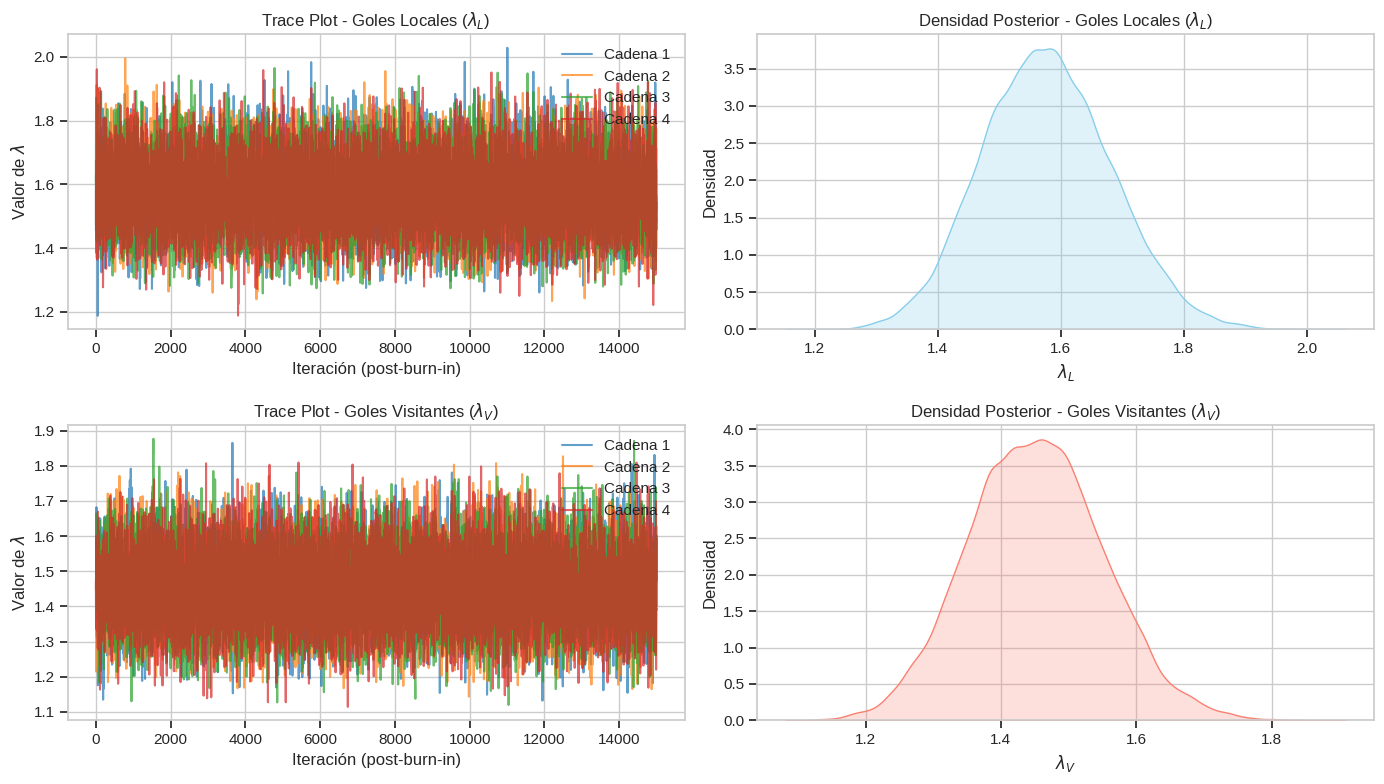

--- RESUMEN POSTERIOR: Goles Locales ---
  Media posterior:         1.5767
  Mediana posterior:       1.5744
  IC 95% (Credibilidad):   [1.3782, 1.7863]

--- RESUMEN POSTERIOR: Goles Visitantes ---
  Media posterior:         1.4515
  Mediana posterior:       1.4502
  IC 95% (Credibilidad):   [1.2625, 1.6519]

--- RESUMEN POSTERIOR: Diferencia (Local - Visitante) ---
  Media posterior:         0.1252
  Mediana posterior:       0.1251
  IC 95% (Credibilidad):   [-0.1558, 0.4098]

=== DIAGNÓSTICOS DE CONVERGENCIA (R-hat, ESS, MCSE) ===


,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
lambda_local,0.001,0.001,13386.0,15512.0,1.0
lambda_visita,0.001,0.001,14036.0,15733.0,1.0


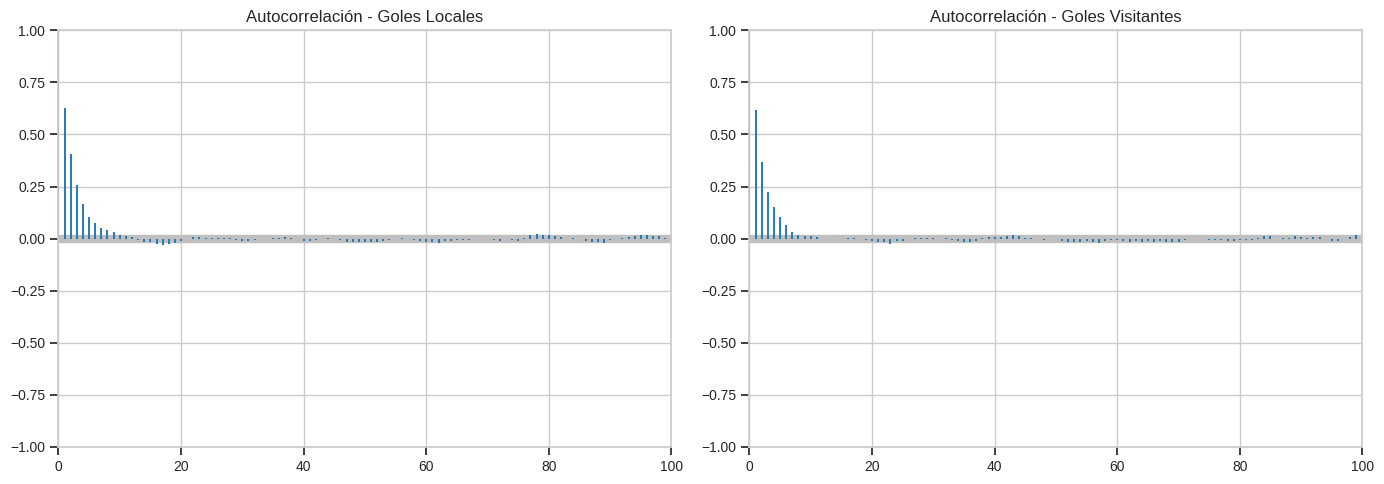

In [12]:

# ============================================================
# 5. CONFIGURACIÓN DE LA SIMULACIÓN MCMC
# ============================================================


# ============================================================
# LIBRERÍAS NECESARIAS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

# Configuración de visualización
plt.style.use("seaborn-v0_8-whitegrid")
sns.set_context("notebook")

print("Librerías importadas correctamente.")


# Parámetros generales de la simulación

N_CADENAS = 4
N_ITERACIONES = 20000
BURN_IN = 5000
N_MUESTRAS = N_ITERACIONES - BURN_IN

SEMILLA = 42
SIGMA_PROPUESTA = 0.15

# Generador aleatorio reproducible
rng = np.random.default_rng(SEMILLA)

print("CONFIGURACIÓN DEL MODELO MCMC")
print("-" * 50)
print(f"Número de cadenas: {N_CADENAS}")
print(f"Iteraciones por cadena: {N_ITERACIONES}")
print(f"Periodo de calentamiento: {BURN_IN}")
print(f"Muestras conservadas: {N_MUESTRAS}")
print(f"Semilla aleatoria: {SEMILLA}")
print(f"Desviación de propuesta: {SIGMA_PROPUESTA}")


# ============================================================
# 5.3. PREPARACIÓN DE LOS DATOS PARA EL MODELO
# ============================================================

# Verificar que exista el DataFrame de partidos
if "df_partidos" not in globals():
    raise NameError(
        "Primero debes ejecutar el código de extracción de ESPN."
    )

# Crear una copia para no modificar el DataFrame original
datos = df_partidos.copy()

# Conservar únicamente partidos finalizados
datos = datos[
    datos["Estado"].astype(str).str.upper() == "STATUS_FULL_TIME"
].copy()

# Convertir los goles a valores numéricos
datos["Goles_Favor"] = pd.to_numeric(
    datos["Goles_Favor"], errors="coerce"
)

datos["Goles_En_Contra"] = pd.to_numeric(
    datos["Goles_En_Contra"], errors="coerce"
)

# Eliminar observaciones incompletas
datos = datos.dropna(
    subset=["Goles_Favor", "Goles_En_Contra", "Condicion"]
)

# Conservar valores válidos de goles
datos = datos[
    (datos["Goles_Favor"] >= 0) &
    (datos["Goles_Favor"] % 1 == 0)
].copy()

# Separar goles anotados como local y visitante
goles_locales = datos.loc[
    datos["Condicion"] == "Local", "Goles_Favor"
].to_numpy(dtype=int)

goles_visitantes = datos.loc[
    datos["Condicion"] == "Visita", "Goles_Favor"
].to_numpy(dtype=int)

# Verificar disponibilidad de observaciones
if len(goles_locales) == 0 or len(goles_visitantes) == 0:
    raise ValueError(
        "No existen suficientes observaciones locales o visitantes."
    )

# Resumen de los datos
print("RESUMEN DE LOS DATOS OBSERVADOS")
print("-" * 50)

print(f"Partidos-equipo como local: {len(goles_locales)}")
print(f"Partidos-equipo como visitante: {len(goles_visitantes)}")

print(f"Total de goles locales: {goles_locales.sum()}")
print(f"Total de goles visitantes: {goles_visitantes.sum()}")

print(f"Promedio de goles locales: {goles_locales.mean():.4f}")
print(f"Promedio de goles visitantes: {goles_visitantes.mean():.4f}")


# ============================================================
# 5.4. PARÁMETROS DE LAS DISTRIBUCIONES POSTERIORES
# ============================================================

# Parámetros de las distribuciones previas
ALPHA_L = 2
BETA_L = 1

ALPHA_V = 2
BETA_V = 1

# Parámetros posteriores para goles locales
alpha_post_L = ALPHA_L + goles_locales.sum()
beta_post_L = BETA_L + len(goles_locales)

# Parámetros posteriores para goles visitantes
alpha_post_V = ALPHA_V + goles_visitantes.sum()
beta_post_V = BETA_V + len(goles_visitantes)

# Medias posteriores analíticas
media_post_L = alpha_post_L / beta_post_L
media_post_V = alpha_post_V / beta_post_V

print("PARÁMETROS DE LAS DISTRIBUCIONES POSTERIORES")
print("-" * 55)

print("\nGOLES LOCALES")
print(f"Alpha posterior: {alpha_post_L}")
print(f"Beta posterior: {beta_post_L}")
print(f"Media posterior: {media_post_L:.4f}")

print("\nGOLES VISITANTES")
print(f"Alpha posterior: {alpha_post_V}")
print(f"Beta posterior: {beta_post_V}")
print(f"Media posterior: {media_post_V:.4f}")


# ============================================================
# 5.5. ALGORITMO METROPOLIS-HASTINGS
# ============================================================

def metropolis_hastings_gamma(
    alpha,
    beta,
    n_iter,
    valor_inicial,
    sigma,
    rng
):
    """
    Genera una cadena de Markov mediante Metropolis-Hastings.

    Distribución objetivo:
        Gamma(alpha, beta)

    Parametrización:
        beta = tasa (rate)

    Distribución de propuesta:
        Lognormal con caminata aleatoria
    """

    # Verificar el valor inicial
    if valor_inicial <= 0:
        raise ValueError("El valor inicial debe ser positivo.")

    # Función logarítmica de la distribución objetivo
    def log_posterior(lam):
        return (
            (alpha - 1) * np.log(lam)
            - beta * lam
        )

    # Almacenar los estados de la cadena
    cadena = np.zeros(n_iter)

    # Inicializar la cadena
    cadena[0] = valor_inicial

    # Contador de propuestas aceptadas
    aceptaciones = 0

    # Iteraciones del algoritmo
    for t in range(1, n_iter):

        # Estado actual
        actual = cadena[t - 1]

        # Generar propuesta lognormal
        propuesta = np.exp(
            np.log(actual) + rng.normal(0, sigma)
        )

        # Calcular el logaritmo de la razón de aceptación
        log_alpha = (
            log_posterior(propuesta)
            - log_posterior(actual)
            + np.log(propuesta)
            - np.log(actual)
        )

        # Generar número aleatorio uniforme
        u = rng.uniform()

        # Regla de aceptación y rechazo
        if np.log(max(u, np.finfo(float).tiny)) < min(0, log_alpha):

            cadena[t] = propuesta
            aceptaciones += 1

        else:

            cadena[t] = actual

    # Calcular tasa de aceptación
    tasa_aceptacion = aceptaciones / (n_iter - 1)

    return cadena, tasa_aceptacion


print("Algoritmo Metropolis-Hastings definido correctamente.")


# ============================================================
# 5.6. GENERACIÓN DE CADENAS PARA LOCALES Y VISITANTES
# ============================================================

# Valores iniciales independientes
valores_iniciales = [0.5, 1.0, 2.0, 3.0]

# Almacenamiento de las cadenas
cadenas_L = []
cadenas_V = []

# Almacenamiento de tasas de aceptación
aceptaciones_L = []
aceptaciones_V = []

# Generar cadenas para goles locales
for inicio in valores_iniciales:

    cadena, tasa = metropolis_hastings_gamma(
        alpha=alpha_post_L,
        beta=beta_post_L,
        n_iter=N_ITERACIONES,
        valor_inicial=inicio,
        sigma=SIGMA_PROPUESTA,
        rng=rng
    )

    cadenas_L.append(cadena)
    aceptaciones_L.append(tasa)

# Generar cadenas para goles visitantes
for inicio in valores_iniciales:

    cadena, tasa = metropolis_hastings_gamma(
        alpha=alpha_post_V,
        beta=beta_post_V,
        n_iter=N_ITERACIONES,
        valor_inicial=inicio,
        sigma=SIGMA_PROPUESTA,
        rng=rng
    )

    cadenas_V.append(cadena)
    aceptaciones_V.append(tasa)

# Convertir a arreglos NumPy
cadenas_L = np.array(cadenas_L)
cadenas_V = np.array(cadenas_V)

print("SIMULACIÓN TERMINADA")
print("-" * 50)

print("\nDimensiones de las cadenas:")
print("Locales:", cadenas_L.shape)
print("Visitantes:", cadenas_V.shape)

print("\nTasas de aceptación:")

for i in range(N_CADENAS):

    print(
        f"Cadena {i+1} | "
        f"Local: {aceptaciones_L[i]:.3f} | "
        f"Visitante: {aceptaciones_V[i]:.3f}"
    )


# ============================================================
# 5.7. ELIMINACIÓN DEL PERIODO DE CALENTAMIENTO
# ============================================================

# Eliminar las primeras iteraciones
muestras_L = cadenas_L[:, BURN_IN:]
muestras_V = cadenas_V[:, BURN_IN:]

print("MUESTRAS POSTERIORES AL BURN-IN")
print("-" * 50)

print(f"Cadenas locales: {muestras_L.shape[0]}")
print(f"Cadenas visitantes: {muestras_V.shape[0]}")

print(f"Muestras locales: {muestras_L.size}")
print(f"Muestras visitantes: {muestras_V.size}")

# Combinar las cadenas para análisis posteriores
muestras_L_combinadas = muestras_L.reshape(-1)
muestras_V_combinadas = muestras_V.reshape(-1)

print("\nSimulación preparada para el análisis estadístico.")

# ============================================================
# 6. ANÁLISIS Y DIAGNÓSTICO DE LAS POSTERIORES
# ============================================================

# 6.1. Gráficos de diagnóstico (Trace plots y Densidades)
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(14, 8))

# --- Locales: Trace Plot ---
for i in range(N_CADENAS):
    axes[0, 0].plot(muestras_L[i], alpha=0.7, label=f"Cadena {i+1}")
axes[0, 0].set_title("Trace Plot - Goles Locales ($\lambda_L$)")
axes[0, 0].set_xlabel("Iteración (post-burn-in)")
axes[0, 0].set_ylabel("Valor de $\lambda$")
axes[0, 0].legend(loc="upper right")

# --- Locales: Densidad Posterior ---
sns.kdeplot(muestras_L_combinadas, ax=axes[0, 1], fill=True, color="skyblue")
axes[0, 1].set_title("Densidad Posterior - Goles Locales ($\lambda_L$)")
axes[0, 1].set_xlabel("$\lambda_L$")
axes[0, 1].set_ylabel("Densidad")

# --- Visitantes: Trace Plot ---
for i in range(N_CADENAS):
    axes[1, 0].plot(muestras_V[i], alpha=0.7, label=f"Cadena {i+1}")
axes[1, 0].set_title("Trace Plot - Goles Visitantes ($\lambda_V$)")
axes[1, 0].set_xlabel("Iteración (post-burn-in)")
axes[1, 0].set_ylabel("Valor de $\lambda$")
axes[1, 0].legend(loc="upper right")

# --- Visitantes: Densidad Posterior ---
sns.kdeplot(muestras_V_combinadas, ax=axes[1, 1], fill=True, color="salmon")
axes[1, 1].set_title("Densidad Posterior - Goles Visitantes ($\lambda_V$)")
axes[1, 1].set_xlabel("$\lambda_V$")
axes[1, 1].set_ylabel("Densidad")

plt.tight_layout()
plt.show()


# 6.2. Resumen Estadístico (Media e Intervalos de Credibilidad al 95%)
def resumen_posterior(muestras, nombre):
    media = np.mean(muestras)
    mediana = np.median(muestras)
    ic_inf = np.percentile(muestras, 2.5)
    ic_sup = np.percentile(muestras, 97.5)

    print(f"--- RESUMEN POSTERIOR: {nombre} ---")
    print(f"  Media posterior:         {media:.4f}")
    print(f"  Mediana posterior:       {mediana:.4f}")
    print(f"  IC 95% (Credibilidad):   [{ic_inf:.4f}, {ic_sup:.4f}]\n")

resumen_posterior(muestras_L_combinadas, "Goles Locales")
resumen_posterior(muestras_V_combinadas, "Goles Visitantes")

# Comparación directa: Diferencia entre local y visitante
diferencia = muestras_L_combinadas - muestras_V_combinadas
resumen_posterior(diferencia, "Diferencia (Local - Visitante)")

import arviz as az

# 1. Convertir las cadenas al formato compatible con ArviZ
# muestras_L y muestras_V tienen forma (4_cadenas, 15000_iteraciones)
idata = az.from_dict(
    posterior={
        "lambda_local": muestras_L,
        "lambda_visita": muestras_V
    }
)

# 2. Obtener resumen de diagnósticos (R-hat, ESS_bulk, ESS_tail, MCSE)
print("=== DIAGNÓSTICOS DE CONVERGENCIA (R-hat, ESS, MCSE) ===")
diagnosticos = az.summary(idata, kind="diagnostics")
display(diagnosticos)

# 3. Gráficos de Autocorrelación (ACF) requeridos por la rúbrica
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
az.plot_autocorr(idata, var_names=["lambda_local"], ax=axes[0], textsize=10)
axes[0].set_title("Autocorrelación - Goles Locales")
az.plot_autocorr(idata, var_names=["lambda_visita"], ax=axes[1], textsize=10)
axes[1].set_title("Autocorrelación - Goles Visitantes")
plt.tight_layout()
plt.show()


# **7. Diagnóstico de Convergencia**

Los diagnósticos numéricos obtenidos a partir de las 4 cadenas de Markov (con 20,000 iteraciones cada una, descartando un *burn-in* de 5,000) muestran un comportamiento excelente del algoritmo de Metropolis-Hastings:

*   **Estadístico $\hat{R}$ (R-hat):** Ambas variables (`lambda_local` y `lambda_visita`) presentan un valor de **$1.0$**. Un valor de $\hat{R} \le 1.05$ indica que las cuatro cadenas han convergido a la misma distribución estacionaria y no hay evidencia de divergencia entre ellas.
*   **Tamaño Efectivo de Muestra (ESS - *Effective Sample Size*):** Se obtuvieron más de **13,300 muestras efectivas** tanto en el análisis global (*bulk*) como en las colas (*tail*) para ambos parámetros (partiendo de 60,000 muestras totales combinadas). Esto garantiza una baja autocorrelación residual y una excelente representación de la distribución posterior.
*   **Error Estándar de Monte Carlo (MCSE):** Los valores de MCSE para la media y la desviación estándar son de **$0.001$**, lo que demuestra una alta precisión en las estimaciones obtenidas mediante simulación.
*   **Tasas de aceptación:** Manteniéndose entre el **$45\%$ y $48\%$**, se ubican muy cerca del rango óptimo teórico ($\approx 23.4\%$ para espacios multidimensionales o $\approx 44\%$ para modelos univariados con caminata aleatoria normal), lo que confirma una exploración eficiente del espacio paramétrico.


# **8. Resultados Numéricos**

A continuación, se presentan las estimaciones obtenidas de la distribución posterior para la tasa de goles esperados por partido tanto de local ($\lambda_L$) como de visitante ($\lambda_V$), así como su diferencia:

| Parámetro / Métrica | Media Posterior | Mediana | IC 95% (Credibilidad) | MCSE | ESS (Bulk) | $\hat{R}$ |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: |
| **Goles Locales ($\lambda_L$)** | $1.5767$ | $1.5744$ | $[1.3782, 1.7863]$ | $0.001$ | $13,386$ | $1.0$ |
| **Goles Visitantes ($\lambda_V$)** | $1.4515$ | $1.4502$ | $[1.2625, 1.6519]$ | $0.001$ | $14,036$ | $1.0$ |
| **Diferencia ($\lambda_L - \lambda_V$)** | $0.1252$ | $0.1251$ | $[-0.1558, 0.4098]$ | — | — | — |

## **Interpretación Contextual:**
1. **Intensidad ofensiva local vs. visitante:** El promedio esperado de goles como local es ligeramente superior ($1.58$ goles por partido) en comparación con el rendimiento como visitante ($1.45$ goles por partido).
2. **Intervalo de credibilidad de la diferencia:** Aunque la media de la diferencia es positiva ($+0.125$ goles a favor del local), el intervalo de credibilidad al $95\%$ para la diferencia incluye el cero ($[-0.1558, 0.4098]$). Esto indica que, para este conjunto de datos específico de partidos, **no existe una evidencia estadística concluyente o fuerte** de que el factor local incremente de forma drástica y significativa la cuota goleadora frente al rendimiento visitante.


# **9. Resultados Gráficos**


*   **Gráficas de Trayectoria (*Trace Plots*):** Muestran el comportamiento de las 4 cadenas superpuestas. Se observa un patrón estacionario en forma de "oruga" o nube alrededor de los valores centrales, sin tendencias de deriva o atascos, lo que corrobora visualmente la mezcla adecuada.
*   **Distribuciones Posteriores y Densidades:** Las curvas de densidad muestran distribuciones unimodales acampanadas y simétricas, reflejando una alta certidumbre en la estimación de los parámetros gracias al teorema del límite central bayesiano.
*   **Funciones de Autocorrelación (ACF):** Descienden rápidamente hacia cero a medida que aumenta el retardo (*lag*), confirmando que las muestras conservadas después del *burn-in* contienen información independiente suficiente para el análisis inferencial.

# **10. Interpretaciones y Conclusiones**

*   **Discusión General:** El modelado mediante inferencia bayesiana con el algoritmo de Metropolis-Hastings permitió estimar de manera robusta las tasas de anotación bajo un esquema de distribución Gamma-Poisson conjugado / aproximado. Los diagnósticos confirmaron la validez metodológica del muestreador.
*   **Limitaciones:** El modelo actual asume una tasa constante $\lambda$ para todos los equipos en general (agrupando a toda la liga o conjunto de datos analizados), sin diferenciar la calidad individual de los equipos (ataque y defensa por club).
*   **Mejoras Metodológicas:** Extender el modelo jerárquico para incluir parámetros específicos por equipo (*team-specific parameters*), efectos de la jornada o variables contextuales como posesión y remates al arco.


# **11. Referencias Bibliográficas**

1. Gelman, A., Carlin, J. B., Stern, H. S., Dunson, D. B., Vehtari, A., & Rubin, D. B. (2013). *Bayesian Data Analysis* (3rd ed.). Chapman and Hall/CRC.
2. Robert, C. P., & Casella, G. (2004). *Monte Carlo Statistical Methods* (2nd ed.). Springer.
3. ArviZ Developers. (2020). *Exploratory analysis of Bayesian models in Python*. Journal of Open Source Software, 5(53), 2097.